VST a nivel oracion 
1. Secuencia de frames (t,c,96,96)
2. CNN - feature extreactor - reducir dimensiones y preservar T 
3. GRU/LSTM - modelado temporal 
4. Clasificación + CTC : 71 clases de caracteres, incluido blank 

In [1]:
import json
import math
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import pyarrow

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

# Reproducibilidad
SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Configuración
CLIPS_DIR = Path(r"D:\ViSpeR\clips")
METADATA_PATH = CLIPS_DIR / "metadata.json"

IMAGE_HEIGHT = 96
IMAGE_WIDTH = 96

INPUT_CHANNELS = 3  # Provisional: mas adelante enfrentamos a grayscale
VOCAB_SIZE = 71     # 70 caracteres + CTC blank

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())
print("Device:", DEVICE)
print("Metadata existe:", METADATA_PATH.exists())
print("Vocabulario:", VOCAB_SIZE)

PyTorch: 2.6.0+cu126
CUDA disponible: True
Device: cuda
Metadata existe: True
Vocabulario: 71


In [2]:
from collections import Counter
from pathlib import Path

with open(METADATA_PATH, "r", encoding="utf-8") as f:
    metadata = json.load(f)

all_text = "".join(
    info["label"] for info in metadata.values()
)

char_counts = Counter(all_text)

characters = sorted(char_counts.keys())

print(f"Cantidad de caracteres distintos: {len(characters)}")
print(f"Cantidad total con CTC blank: {len(characters) + 1}")
print("\nVocabulario:")
for i, char in enumerate(characters, start=1):
    print(f"{i:2} | {repr(char):8} | frecuencia: {char_counts[char]}")

print("\nCTC blank: 0")

Cantidad de caracteres distintos: 70
Cantidad total con CTC blank: 71

Vocabulario:
 1 | ' '      | frecuencia: 16524
 2 | '0'      | frecuencia: 57
 3 | '1'      | frecuencia: 29
 4 | '2'      | frecuencia: 29
 5 | '3'      | frecuencia: 14
 6 | '4'      | frecuencia: 11
 7 | '5'      | frecuencia: 18
 8 | '6'      | frecuencia: 3
 9 | '7'      | frecuencia: 2
10 | '8'      | frecuencia: 11
11 | '9'      | frecuencia: 8
12 | 'A'      | frecuencia: 72
13 | 'B'      | frecuencia: 25
14 | 'C'      | frecuencia: 97
15 | 'D'      | frecuencia: 29
16 | 'E'      | frecuencia: 139
17 | 'F'      | frecuencia: 12
18 | 'G'      | frecuencia: 17
19 | 'H'      | frecuencia: 26
20 | 'I'      | frecuencia: 15
21 | 'J'      | frecuencia: 6
22 | 'K'      | frecuencia: 10
23 | 'L'      | frecuencia: 56
24 | 'M'      | frecuencia: 51
25 | 'N'      | frecuencia: 47
26 | 'O'      | frecuencia: 18
27 | 'P'      | frecuencia: 86
28 | 'Q'      | frecuencia: 27
29 | 'R'      | frecuencia: 18
30 | 'S'      | f

In [3]:
IMAGE_MODE = "rgb"
INPUT_CHANNELS = 3

IMAGE_HEIGHT = 96
IMAGE_WIDTH = 96

BLANK_IDX = 0
VOCAB_SIZE = len(characters) + 1

print("Modo de imagen:", IMAGE_MODE)
print("Canales de entrada:", INPUT_CHANNELS)
print("Resolución:", IMAGE_HEIGHT, "x", IMAGE_WIDTH)
print("Tamaño del vocabulario:", VOCAB_SIZE)

Modo de imagen: rgb
Canales de entrada: 3
Resolución: 96 x 96
Tamaño del vocabulario: 71


#DATA

In [4]:
DATA_DIR = Path("data")

clips_df = pd.read_parquet(DATA_DIR / "clips_metadata.parquet")
clips_df["path"] = clips_df["path"].apply(Path)

with open(DATA_DIR / "vocabulary.json", "r", encoding="utf-8") as f:
    char_to_idx = json.load(f)

idx_to_char = {
    int(idx): char
    for char, idx in char_to_idx.items()
}

BLANK_IDX = 0
VOCAB_SIZE = len(char_to_idx) + 1

print("Clips:", len(clips_df))
print("Vocabulario:", VOCAB_SIZE)
print("Primer registro:")
display(clips_df.head(1))

Clips: 1304
Vocabulario: 71
Primer registro:


,path,label,frames,ctc_min_frames,repeated_pairs,temporal_margin,min_temporal_ratio,duration_seconds,words_per_second,video_id,is_ctc_problematic,frames_after_x1,margin_after_x1,frames_after_x2,margin_after_x2,frames_after_x3,margin_after_x3,frames_after_x4,margin_after_x4
0,D:\ViSpeR\clips\videos\0YEeb-WLF2w\00000.mp4,La ficción es una herramienta poderosa,108,41,2,67,0.37963,4.32,1.388889,0YEeb-WLF2w,False,108,67,54,13,36,-5,27,-14


In [5]:
class ViSpeRDataset(Dataset):
    def __init__(self, dataframe):
        self.dataframe = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        cap = cv2.VideoCapture(str(row["path"]))

        if not cap.isOpened():
            raise RuntimeError(f"No se pudo abrir: {row['path']}")

        frames = []

        while True:
            ret, frame = cap.read()

            if not ret:
                break

            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frames.append(frame)

        cap.release()

        if not frames:
            raise RuntimeError(f"El clip no contiene frames: {row['path']}")

        video = np.stack(frames).astype(np.float32) / 255.0
        video = torch.from_numpy(video).permute(0, 3, 1, 2)

        target = torch.tensor(
            [char_to_idx[char] for char in str(row["label"])],
            dtype=torch.long
        )

        return {
            "video": video,
            "target": target,
            "input_length": video.shape[0],
            "target_length": target.numel(),
            "text": str(row["label"]),
            "path": str(row["path"])
        }

la STCNN va a procesar grupos de frames simultaneamente (menos mal)
Los videos tienen 3 dim relevantes_> h,w,t
conv3d , cada frame va a observar una secuencia, y va a extraer caract de eso
approx 1 +3(3-1) /(25fps) = 0.28s de contexto local 

In [6]:
class STCNN(nn.Module):
    def __init__(self, in_channels=3):
        super().__init__()

        self.block1 = nn.Sequential(
            nn.Conv3d(
                in_channels, 32,
                kernel_size=(3, 5, 5),
                stride=(1, 2, 2),
                padding=(1, 2, 2)
            ),
            nn.ReLU(),
            nn.MaxPool3d(
                kernel_size=(1, 2, 2),
                stride=(1, 2, 2)
            ),
            nn.Dropout3d(p=0.5)
        )

        self.block2 = nn.Sequential(
            nn.Conv3d(
                32, 64,
                kernel_size=(3, 5, 5),
                stride=(1, 1, 1),
                padding=(1, 2, 2)
            ),
            nn.ReLU(),
            nn.MaxPool3d(
                kernel_size=(1, 2, 2),
                stride=(1, 2, 2)
            ),
            nn.Dropout3d(p=0.5)
        )

        self.block3 = nn.Sequential(
            nn.Conv3d(
                64, 96,
                kernel_size=(3, 3, 3),
                stride=(1, 1, 1),
                padding=(1, 1, 1)
            ),
            nn.ReLU(),
            nn.MaxPool3d(
                kernel_size=(1, 2, 2),
                stride=(1, 2, 2)
            ),
            nn.Dropout3d(p=0.5)
        )

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        return x

In [7]:
# test ficticio 
model_cnn = STCNN(in_channels=INPUT_CHANNELS)

x = torch.randn(2, 3, 75, 96, 96)

with torch.no_grad():
    features = model_cnn(x)

print("Input:", x.shape)
print("Output:", features.shape)

assert features.shape == (2, 96, 75, 6, 6)

print("Dimensiones verificadas correctamente.")

Input: torch.Size([2, 3, 75, 96, 96])
Output: torch.Size([2, 96, 75, 6, 6])
Dimensiones verificadas correctamente.


### preparar la salida a la recurrente 
$ F = 96 \times 6 \times 6 = 3456 $  

cada frame va a quedar representado por un vector de 3456 características. nothermione,notme,you

In [8]:
# (B, C, T, H, W) -> (T, B, C, H, W)
features = features.permute(2, 0, 1, 3, 4)

# (T, B, C, H, W) -> (T, B, F)
features = features.reshape(
    features.shape[0],
    features.shape[1],
    -1
)

print("Features para la RNN:", features.shape)

assert features.shape == (75, 2, 3456)

Features para la RNN: torch.Size([75, 2, 3456])


In [9]:
class TemporalEncoder(nn.Module):
    def __init__(
        self,
        input_size=3456,
        hidden_size=256,
        num_layers=2,
        rnn_type="gru"
    ):
        super().__init__()

        if rnn_type.lower() == "gru":
            rnn_class = nn.GRU
        elif rnn_type.lower() == "lstm":
            rnn_class = nn.LSTM
        else:
            raise ValueError("rnn_type debe ser 'gru' o 'lstm'")

        self.rnn = rnn_class(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            bidirectional=True,
            batch_first=False
        )

    def forward(self, x, lengths):
        packed = pack_padded_sequence(
            x,
            lengths.cpu(),
            batch_first=False,
            enforce_sorted=False
        )

        packed_output, _ = self.rnn(packed)

        output, _ = pad_packed_sequence(
            packed_output,
            batch_first=False,
            total_length=x.size(0)
        )

        return output

In [10]:
class CharacterClassifier(nn.Module):
    def __init__(self, input_size=512, vocab_size=VOCAB_SIZE):
        super().__init__()
        self.linear = nn.Linear(input_size, vocab_size)

    def forward(self, x):
        return self.linear(x)

#cosillas:
la entrada es lo que devuelve el dataLoader -> $(B,T,C,H,W)$
La salida queda en (T,B,V), que es el formato que quiere CTCLoss

In [11]:
class LipReadingModel(nn.Module):
    def __init__(
        self,
        in_channels=3,
        vocab_size=VOCAB_SIZE,
        hidden_size=256,
        rnn_type="gru"
    ):
        super().__init__()

        self.visual_encoder = STCNN(in_channels=in_channels)

        self.temporal_encoder = TemporalEncoder(
            input_size=96 * 6 * 6,
            hidden_size=hidden_size,
            num_layers=2,
            rnn_type=rnn_type
        )

        self.classifier = CharacterClassifier(
            input_size=hidden_size * 2,
            vocab_size=vocab_size
        )

    def forward(self, x, input_lengths):
        # B,T,C,H,W -> B,C,T,H,W
        x = x.permute(0, 2, 1, 3, 4)

        # Extracción de características espacio-temporales
        x = self.visual_encoder(x)

        # B,C,T,H,W -> T,B,C*H*W
        x = x.permute(2, 0, 1, 3, 4)
        x = x.reshape(x.shape[0], x.shape[1], -1)

        # Modelado temporal respetando las longitudes reales
        x = self.temporal_encoder(x, input_lengths)

        # Clasificación por timestep
        x = self.classifier(x)

        return torch.log_softmax(x, dim=-1)

In [12]:
train_dataset = ViSpeRDataset(clips_df) 

sample = train_dataset[0]

print("Video:", sample["video"].shape)
print("Tipo:", sample["video"].dtype)
print("Rango:", sample["video"].min().item(), sample["video"].max().item())
print("Target:", sample["target"].shape)
print("Texto:", sample["text"])

assert sample["video"].ndim == 4
assert sample["video"].shape[1:] == (3, 96, 96)
assert sample["video"].dtype == torch.float32
assert sample["target"].numel() == len(sample["text"])

print("\nValidación correcta.")

Video: torch.Size([108, 3, 96, 96])
Tipo: torch.float32
Rango: 0.0 1.0
Target: torch.Size([39])
Texto:  La ficción es una herramienta poderosa

Validación correcta.


In [13]:
def collate_fn(batch):
    videos = [item["video"] for item in batch]
    targets = [item["target"] for item in batch]

    input_lengths = torch.tensor(
        [video.shape[0] for video in videos],
        dtype=torch.long
    )

    target_lengths = torch.tensor(
        [target.numel() for target in targets],
        dtype=torch.long
    )

    max_frames = input_lengths.max().item()

    padded_videos = torch.zeros(
        len(batch),
        max_frames,
        *videos[0].shape[1:],
        dtype=torch.float32
    )

    for i, video in enumerate(videos):
        padded_videos[i, :video.shape[0]] = video

    concatenated_targets = torch.cat(targets)

    return {
        "videos": padded_videos,
        "targets": concatenated_targets,
        "input_lengths": input_lengths,
        "target_lengths": target_lengths,
        "texts": [item["text"] for item in batch],
        "paths": [item["path"] for item in batch]
    }

In [14]:
BATCH_SIZE = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0
)

batch = next(iter(train_loader))

print("Videos:", batch["videos"].shape)
print("Targets:", batch["targets"].shape)
print("Input lengths:", batch["input_lengths"])
print("Target lengths:", batch["target_lengths"])
print("Transcripciones:")

for text in batch["texts"]:
    print(repr(text))

Videos: torch.Size([2, 108, 3, 96, 96])
Targets: torch.Size([61])
Input lengths: tensor([108,  82])
Target lengths: tensor([39, 22])
Transcripciones:
' La ficción es una herramienta poderosa'
' Una tecnología blanda'


In [17]:
from torch.nn.utils.rnn import (
    pack_padded_sequence,
    pad_packed_sequence
)

blank=0: indice blank  
reduction="mean": promedia la pérdida del batch.  
zero_infinity=True: evita que pérdidas infinitas por alineaciones imposibles contaminen el entrenamiento.  

In [19]:
# la funcion de perdida 
ctc_loss = nn.CTCLoss(
    blank=BLANK_IDX,
    reduction="mean",
    zero_infinity=True
)

In [21]:
model = LipReadingModel(
    in_channels=3,
    vocab_size=VOCAB_SIZE,
    hidden_size=256,
    rnn_type="gru"
).to(DEVICE)

model.eval()

videos = batch["videos"].to(DEVICE)
input_lengths = batch["input_lengths"]

with torch.no_grad():
    log_probs = model(videos, input_lengths)

print("Entrada:", videos.shape)
print("Salida:", log_probs.shape)
print("Longitudes reales:", input_lengths.tolist())
print("NaN:", torch.isnan(log_probs).any().item())
print("Inf:", torch.isinf(log_probs).any().item())

Entrada: torch.Size([2, 108, 3, 96, 96])
Salida: torch.Size([108, 2, 71])
Longitudes reales: [108, 82]
NaN: False
Inf: False


In [22]:
targets = batch["targets"].to(DEVICE)
input_lengths = batch["input_lengths"]
target_lengths = batch["target_lengths"]

loss = ctc_loss(
    log_probs,
    targets,
    input_lengths,
    target_lengths
)

print("CTC Loss:", loss.item())
print("Loss finita:", torch.isfinite(loss).item())

CTC Loss: 11.120353698730469
Loss finita: True


## TRAIN

Época 1/5 | Loss: 3.0749 | Batches: 652/652
Época 2/5 | Loss: 2.9841 | Batches: 652/652
Época 3/5 | Loss: 2.9737 | Batches: 652/652
Época 4/5 | Loss: 2.9653 | Batches: 652/652
Época 5/5 | Loss: 2.9594 | Batches: 652/652


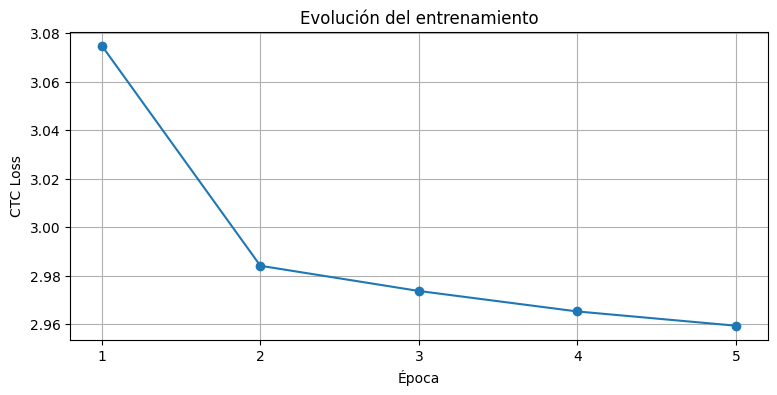

In [28]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim

EPOCHS = 5

ctc_loss = nn.CTCLoss(
    blank=BLANK_IDX,
    reduction="mean",
    zero_infinity=True
)

optimizer = optim.Adam(
    model.parameters(),
    lr=1e-4
)

history = []

for epoch in range(EPOCHS):

    model.train()
    total_loss = 0.0
    valid_batches = 0

    for batch_idx, batch in enumerate(train_loader):

        videos = batch["videos"].to(DEVICE)
        targets = batch["targets"].to(DEVICE)

        input_lengths = batch["input_lengths"]
        target_lengths = batch["target_lengths"]

        optimizer.zero_grad()

        log_probs = model(videos, input_lengths)

        loss = ctc_loss(
            log_probs,
            targets,
            input_lengths,
            target_lengths
        )

        if not torch.isfinite(loss):
            continue

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=5.0
        )

        optimizer.step()

        total_loss += loss.item()
        valid_batches += 1

    epoch_loss = total_loss / valid_batches
    history.append(epoch_loss)

    print(
        f"Época {epoch + 1}/{EPOCHS} | "
        f"Loss: {epoch_loss:.4f} | "
        f"Batches: {valid_batches}/{len(train_loader)}"
    )

plt.figure(figsize=(9, 4))
plt.plot(range(1, EPOCHS + 1), history, marker="o")
plt.xlabel("Época")
plt.ylabel("CTC Loss")
plt.title("Evolución del entrenamiento")
plt.xticks(range(1, EPOCHS + 1))
plt.grid(True)
plt.show()

## eval

,Referencia,Predicción
0,La ficción es una herramienta poderosa,as
1,Una tecnología blanda,as
2,Las tecnologías blandas funcionan de la misma...,as
3,Cuando en las historias de la Biblia se nos c...,as
4,que las cosas buenas son recompensadas y las ...,as
...,...,...
1299,Lo bueno de este método por lo menos en mi ex...,as
1300,es que deja muy buen sabor de boca sin probar...,as
1301,Alivia el insomio y el estrés sin tener que t...,as
1302,Ves de cerca sin microscopio y de lejos sin t...,as


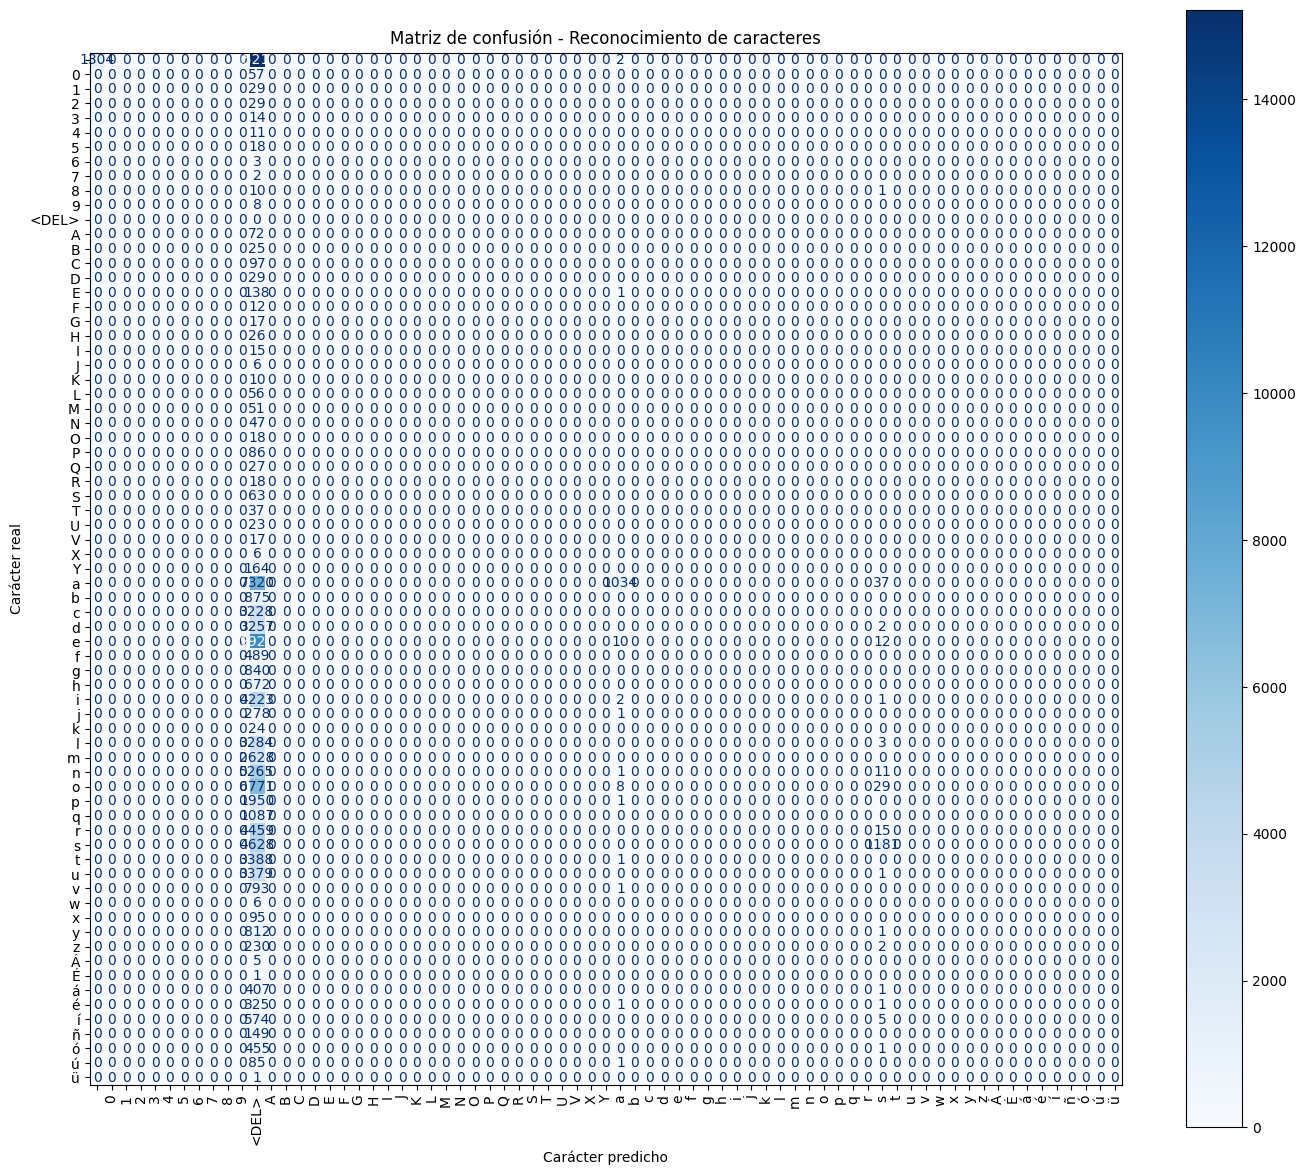

In [29]:
import torch
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


# --------------------------------------------------
# 1. Decodificación greedy de CTC
# --------------------------------------------------

def greedy_decode(log_probs, input_length):
    predictions = log_probs[:input_length].argmax(dim=-1).tolist()

    decoded = []
    previous = None

    for token in predictions:
        if token != previous and token != BLANK_IDX:
            decoded.append(idx_to_char[token])

        previous = token

    return "".join(decoded)


# --------------------------------------------------
# 2. Alineación mediante distancia de edición
# --------------------------------------------------

def align_sequences(reference, prediction):
    n, m = len(reference), len(prediction)

    dp = [[0] * (m + 1) for _ in range(n + 1)]

    for i in range(n + 1):
        dp[i][0] = i

    for j in range(m + 1):
        dp[0][j] = j

    for i in range(1, n + 1):
        for j in range(1, m + 1):
            cost = 0 if reference[i-1] == prediction[j-1] else 1

            dp[i][j] = min(
                dp[i-1][j-1] + cost,  # Sustitución
                dp[i-1][j] + 1,      # Eliminación
                dp[i][j-1] + 1       # Inserción
            )

    pairs = []
    i, j = n, m

    while i > 0 or j > 0:
        if i > 0 and j > 0:
            cost = 0 if reference[i-1] == prediction[j-1] else 1

            if dp[i][j] == dp[i-1][j-1] + cost:
                pairs.append((reference[i-1], prediction[j-1]))
                i -= 1
                j -= 1
                continue

        if i > 0 and dp[i][j] == dp[i-1][j] + 1:
            pairs.append((reference[i-1], "<DEL>"))
            i -= 1
        else:
            pairs.append(("<INS>", prediction[j-1]))
            j -= 1

    return pairs[::-1]


# --------------------------------------------------
# 3. Evaluación de todos los batches
# --------------------------------------------------

model.eval()

y_true = []
y_pred = []
results = []

with torch.no_grad():

    for batch in train_loader:

        videos = batch["videos"].to(DEVICE)
        input_lengths = batch["input_lengths"]

        log_probs = model(videos, input_lengths)

        targets = batch["targets"].tolist()
        target_lengths = batch["target_lengths"].tolist()

        offset = 0

        for i in range(len(target_lengths)):

            target_length = target_lengths[i]

            reference_ids = targets[offset:offset + target_length]
            offset += target_length

            reference = "".join(
                idx_to_char[token] for token in reference_ids
            )

            prediction = greedy_decode(
                log_probs[:, i, :],
                input_lengths[i].item()
            )

            results.append({
                "Referencia": reference,
                "Predicción": prediction
            })

            aligned = align_sequences(reference, prediction)

            for true_char, pred_char in aligned:
                y_true.append(true_char)
                y_pred.append(pred_char)


# --------------------------------------------------
# 4. Mostrar transcripciones
# --------------------------------------------------

display(pd.DataFrame(results))


# --------------------------------------------------
# 5. Construir matriz de confusión
# --------------------------------------------------

labels = sorted(set(y_true + y_pred))

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=labels
)

fig, ax = plt.subplots(figsize=(14, 12))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    colorbar=True
)

ax.set_title("Matriz de confusión - Reconocimiento de caracteres")
ax.set_xlabel("Carácter predicho")
ax.set_ylabel("Carácter real")

plt.tight_layout()
plt.show()

In [30]:
model.eval()

batch = next(iter(train_loader))

videos = batch["videos"].to(DEVICE)
input_lengths = batch["input_lengths"]

with torch.no_grad():
    log_probs = model(videos, input_lengths)

# Primer video
probs = log_probs[:, 0, :].exp()
predictions = probs.argmax(dim=-1)

print("Frames reales:", input_lengths[0].item())
print("Caracteres distintos:", predictions.unique().numel())

print("\nDistribución de predicciones:")
unique, counts = predictions.unique(return_counts=True)

for idx, count in zip(unique.tolist(), counts.tolist()):
    char = idx_to_char[idx] if idx != BLANK_IDX else "<BLANK>"
    print(f"{char!r}: {count} ({count / len(predictions) * 100:.1f}%)")

Frames reales: 108
Caracteres distintos: 4

Distribución de predicciones:
'<BLANK>': 104 (96.3%)
' ': 2 (1.9%)
'a': 1 (0.9%)
's': 1 (0.9%)


In [31]:
print("Batches:", len(train_loader))
print("Clips:", len(train_loader.dataset))
print("Batch size:", train_loader.batch_size)

Batches: 652
Clips: 1304
Batch size: 2
